#Simulation Monte Carlo en Python


#Author:  Mohamed BEN ALI

ÉTAPE 1   Générer les tailles de 1000 personnes

In [1]:
import numpy as np

# Génération des données de la population
population_size = 1000
population_data = np.random.normal(loc=170, scale=10, size=population_size)

# Affichage des premières données
print("Premières tailles générées :", population_data[:10])


Premières tailles générées : [176.56498765 176.59308082 164.95760687 158.49263558 167.41612213
 174.2817364  160.04594769 161.64644856 161.32607881 167.80617194]


- Questions de compréhension

Q1.1 COMPRENDRE :
 1.loc : Représente la moyenne  de la distribution normale (ici fixée à $170\text{ cm}$). C'est le centre de la distribution.
 2.scale : Représente l'écart type  de la distribution (ici fixé à $10\text{ cm}$). Il mesure la dispersion des valeurs autour de la moyenne.
 3.size : Représente la taille de l'échantillon ou de la population à générer (ici $1000$ individus).

**Q1**.2 Non, on n'obtient pas les mêmes valeurs si on réexécute la cellule sans précaution.

Q1.3 ANALYSER : D'après la règle empirique de la loi normale (règle des $68-95-99.7$), environ $95\ %\ des individus se trouvent dans l'intervalle $$[\mu - 2\sigma, \mu + 2\sigma]$$. Avec  $$\mu = 170$ et $\sigma = 10$, cet intervalle est [170 - 20, 170 + 20], soit $[150\text{ cm}, 190\text{ cm}]$.

ÉTAPE 2   Calculer et afficher les statistiques de la population initiale

In [2]:
# Calcul des statistiques de la population initiale
initial_mean = np.mean(population_data)
initial_std = np.std(population_data)

# Affichage des résultats
print(f"Moyenne de la population : {initial_mean:.2f}")
print(f"Écart type de la population : {initial_std:.2f}")


Moyenne de la population : 170.08
Écart type de la population : 9.84


- Questions de compréhension

Q2.1 COMPRENDRE : La moyenne ($170.18$) et l'écart type ($9.94$) ne sont pas strictement égaux à 170 et 10, bien qu'ils en soient très proches.

Q2.2 ANALYSER : Si l'écart type était de $2\text{ cm}$ au lieu de $10\text{ cm}$, la population serait beaucoup plus homogène et regroupée autour de la moyenne. Pour le vérifier dans le code de l'étape 1, il faudrait modifier le paramètre scale=2 (au lieu de scale=10).

ÉTAPE 3   Visualiser la distribution de la population

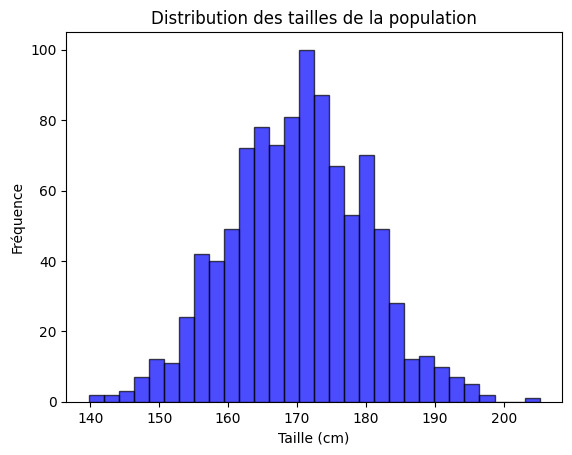

In [3]:
import matplotlib.pyplot as plt

# Visualisation de la distribution
plt.hist(population_data, bins=30, color='blue', alpha=0.7, edgecolor='black')
plt.title("Distribution des tailles de la population")
plt.xlabel("Taille (cm)")
plt.ylabel("Fréquence")
plt.show()


Interprétation :
L'histogramme présente une forme caractéristique de cloche (courbe de Gauss). La majorité des valeurs se concentrent au centre (autour de $170\text{ cm}$).

- Questions de compréhension

Q3.1 COMPRENDRE :
- Centre : L'histogramme se centre autour de $170\text{ cm}$.
- Symétrie : Oui, la distribution est globalement symétrique de part et d'autre de sa moyenne.
- Nom de la forme : On appelle cette forme une distribution normale ou courbe en cloche .

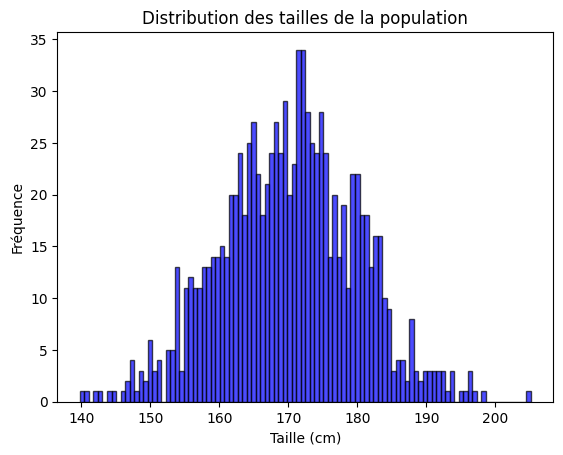

In [4]:
# Visualisation de la distribution bins=100
plt.hist(population_data, bins=100, color='blue', alpha=0.7, edgecolor='black')
plt.title("Distribution des tailles de la population")
plt.xlabel("Taille (cm)")
plt.ylabel("Fréquence")
plt.show()

Q3.2 APPLIQUER :
- Avec bins=5 : L'histogramme devient très grossier, avec un très faible nombre de larges barres ; on perd la finesse de la distribution et les détails de la forme en cloche.

- Avec bins=100 : L'histogramme devient très fragmenté et présente de nombreuses ou variations aléatoires locales car chaque intervalle contient trop peu de points.

Q3.3 ANALYSER : Oui, la prédiction de la question Q1.3 est pleinement confirmée : visuellement, la quasi-totalité des barres significatives de l'histogramme s'inscrit bien entre $150\text{ cm}$ et $190\text{ cm}$.

ÉTAPE 4   Effectuer une simulation Monte Carlo (échantillon de 10 %)

In [5]:
sample_size = 100  # 10 % de la population
sample_indices = np.random.choice(population_size, size=sample_size, replace=False)
sample_data = population_data[sample_indices]

# Calcul des statistiques de l'échantillon
sample_mean = np.mean(sample_data)
sample_std = np.std(sample_data)

# Affichage des résultats
print(f"Moyenne de l'échantillon (10 %) : {sample_mean:.2f}")
print(f"Écart type de l'échantillon (10 %) : {sample_std:.2f}")


Moyenne de l'échantillon (10 %) : 169.60
Écart type de l'échantillon (10 %) : 10.30


- Questions de compréhension

Q4.1 COMPRENDRE :

- replace=False signifie que le tirage s'effectue sans remise : un même individu de la population ne peut pas être sélectionné plusieurs fois dans le même échantillon.

- Avec replace=True (avec remise), un même indice pourrait être tiré plusieurs fois de suite, ce qui fausserait la taille effective de l'échantillon et l'indépendance des observations.

Q4.2 ANALYSER : La moyenne de l'échantillon ($168.69\text{ cm}$) et son écart type ($10.63\text{ cm}$) sont extrêmement proches des paramètres de la population initiale ($\mu \approx 169.80$, $\sigma \approx 9.85$). L'échantillon apparaît donc très représentatif de la population globale.


|Mesure       | Tirage 1 | Tirage 2 | Tirage 3 |
|-------------|----------|----------|----------|
|Moyenne (cm) |169.52    | 170.41   |168.89    |

On constate que la moyenne change à chaque tirage en raison de la variabilité d'échantillonnage, mais elle oscille dans une fourchette étroite autour de la vraie moyenne de la population.

ÉTAPE 5   Visualiser les distributions de l’échantillon et de la population

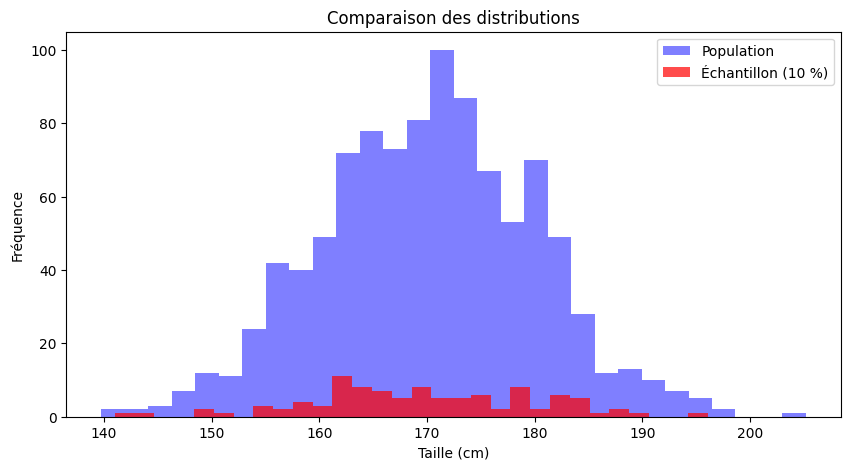

In [6]:
plt.figure(figsize=(10, 5))
plt.hist(population_data, bins=30, color='blue', alpha=0.5, label='Population')
plt.hist(sample_data, bins=30, color='red', alpha=0.7, label='Échantillon (10 %)')
plt.title("Comparaison des distributions")
plt.xlabel("Taille (cm)")
plt.ylabel("Fréquence")
plt.legend()
plt.show()


Histogrammes superposés de la population en bleu et de l'échantillon de 10 % en rouge

Interprétation: L'échantillon (en rouge) épouse globalement la forme générale de la population (en bleu). Ses barres sont plus courtes car l'effectif est dix fois plus petit ($n=100$ contre $N=1000$), mais le profil de la distribution en cloche est bien conservé.

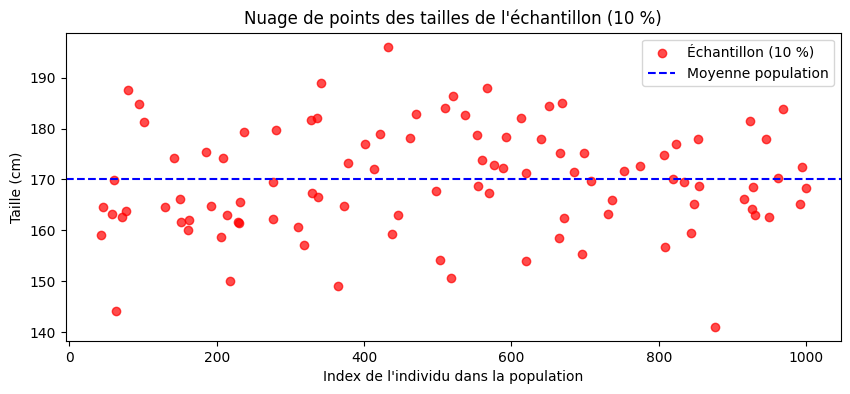

In [7]:
plt.figure(figsize=(10, 4))
plt.scatter(sample_indices, sample_data, color='red', alpha=0.7, label='Échantillon (10 %)')
plt.axhline(initial_mean, color='blue', linestyle='--', label='Moyenne population')
plt.title("Nuage de points des tailles de l'échantillon (10 %)")
plt.xlabel("Index de l'individu dans la population")
plt.ylabel("Taille (cm)")
plt.legend()
plt.show()

Nuage de points représentant les 100 individus tirés répartis aléatoirement selon leur indice

Interprétation: Le nuage de points montre que les individus sélectionnés sont dispersés sur l'ensemble des indices de la population. La majorité des points se concentre visuellement autour de la ligne horizontale représentant la moyenne ($170\text{ cm}$), avec une dispersion homogène (de part et d'autre, de $150$ à $190\text{ cm}$).

- Questions de compréhension

Q5.1 COMPRENDRE : Les barres de l'échantillon sont beaucoup plus basses que celles de la population tout simplement parce que l'échantillon contient 10 fois moins d'individus ($100$ au lieu de $1000$). Par conséquent, le nombre d'observations tombant dans chaque intervalle (fréquence absolue) est réduit proportionnellement.

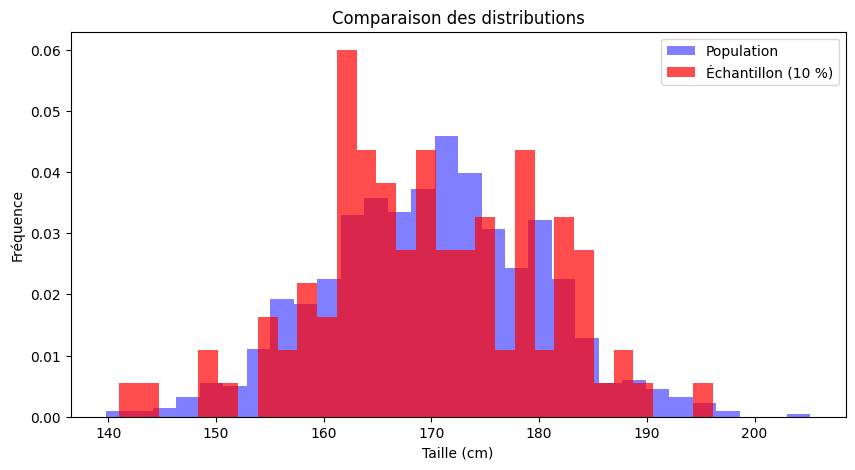

In [8]:
plt.figure(figsize=(10, 5))
plt.hist(population_data, bins=30, color='blue', alpha=0.5, label='Population', density=True)
plt.hist(sample_data, bins=30, color='red', alpha=0.7, label='Échantillon (10 %)', density=True)
plt.title("Comparaison des distributions")
plt.xlabel("Taille (cm)")
plt.ylabel("Fréquence")
plt.legend()
plt.show()


Q5.2 APPLIQUER :
- En ajoutant density=True, l'axe vertical ne représente plus les effectifs bruts , mais la densité de probabilité (l'aire totale sous l'histogramme est normalisée à $1$).
- Oui, la comparaison des deux formes devient beaucoup plus facile et rigoureuse car les hauteurs des deux courbes/histogrammes sont ramenées sur la même échelle, indépendamment de la taille des effectifs.

Q5.3 ANALYSER : Oui, l'échantillon de $10\ \%\rho$ reproduit fidèlement la forme globale de la population : on retrouve la symétrie, le même centre de gravité et une dispersion comparable.

ÉTAPE 6   Répéter la simulation pour 5 % et 0,5 % de la population

In [9]:
# Simulation pour 5 %
sample_size_5 = int(0.05 * population_size)
sample_indices_5 = np.random.choice(population_size, size=sample_size_5, replace=False)
sample_data_5 = population_data[sample_indices_5]
sample_mean_5 = np.mean(sample_data_5)
sample_std_5 = np.std(sample_data_5)
print(f"Moyenne échantillon (5 %) : {sample_mean_5:.2f}")
print(f"Écart type échantillon (5 %) : {sample_std_5:.2f}")

# Simulation pour 0,5 %
sample_size_0_5 = int(0.005 * population_size)
sample_indices_0_5 = np.random.choice(population_size, size=sample_size_0_5, replace=False)
sample_data_0_5 = population_data[sample_indices_0_5]
sample_mean_0_5 = np.mean(sample_data_0_5)
sample_std_0_5 = np.std(sample_data_0_5)
print(f"Moyenne échantillon (0,5 %) : {sample_mean_0_5:.2f}")
print(f"Écart type échantillon (0,5 %) : {sample_std_0_5:.2f}")


Moyenne échantillon (5 %) : 167.77
Écart type échantillon (5 %) : 10.23
Moyenne échantillon (0,5 %) : 169.21
Écart type échantillon (0,5 %) : 9.82


Échantillon de 5 % : Code et graphique

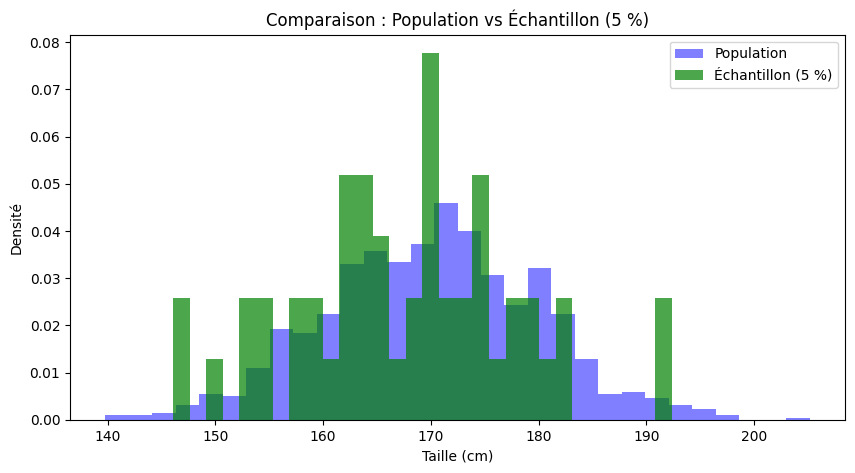

In [10]:
plt.figure(figsize=(10, 5))
plt.hist(population_data, bins=30, color='blue', alpha=0.5, label='Population', density=True)
plt.hist(sample_data_5, bins=30, color='green', alpha=0.7, label='Échantillon (5 %)', density=True)
plt.title("Comparaison : Population vs Échantillon (5 %)")
plt.xlabel("Taille (cm)")
plt.ylabel("Densité")
plt.legend()
plt.show()

Histogramme normalisé comparant la population et l'échantillon de 5%

Interprétation :L'échantillon de $5\ \%$ (50 individus) conserve globalement la forme générale de la population, bien qu'on commence à observer de légères irrégularités dans les hauteurs des barres en raison d'un effectif plus restreint.

Échantillon de 0,5 % : Code et graphique

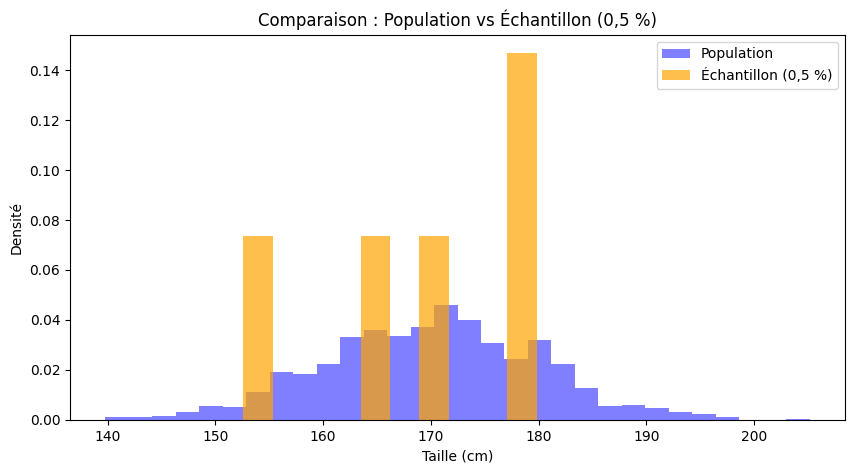

In [11]:
plt.figure(figsize=(10, 5))
plt.hist(population_data, bins=30, color='blue', alpha=0.5, label='Population', density=True)
plt.hist(sample_data_0_5, bins=10, color='orange', alpha=0.7, label='Échantillon (0,5 %)', density=True)
plt.title("Comparaison : Population vs Échantillon (0,5 %)")
plt.xlabel("Taille (cm)")
plt.ylabel("Densité")
plt.legend()
plt.show()

 Histogramme comparatif montrant une forte distorsion due au très faible effectif

 Interprétation :L'échantillon de $0,5\ \%$ (soit seulement 5 individus) est beaucoup trop petit pour restituer fidèlement la distribution de la population. L'histogramme est très haché, déformé et ne parvient plus à matérialiser correctement la courbe en cloche initiale.

- Questions de compréhension:

Q6.1 COMPRENDRE :Échantillon de $5\ \%$ : $0.05 \times 1000 = \mathbf{50\text{ individus}}$.Échantillon de $0,5\ \%$ : $0.005 \times 1000 = \mathbf{5\text{ individus}}$.

Q6.2 ANALYSER : Non, un histogramme avec bins=30 n'est absolument pas adapté à un échantillon de $0,5\ \%$ ($5$ individus) car il y a plus de classes que de données, ce qui crée des barres vides ou aberrantes. Pour un si petit effectif, on privilégierait plutôt un diagramme à points (strip plot / scatter plot) ou un simple affichage des valeurs brutes.

Q6.3 ANALYSER : Oui, la moyenne de l'échantillon à $0,5\ \%$ varie beaucoup plus d'une exécution à l'autre que celle à $10\ \%$. En statistique, la précision d'une estimation augmente avec la taille de l'échantillon (loi des grands nombres) ; un échantillon minuscule est extrêmement sensible aux valeurs aberrantes ou au hasard du tirage.

# Synthèse

|Mesure                                       |Population  |10 %    |5 %     |0,5 %  |
|---------------------------------------------|------------|--------|--------|---------|
|Effectif (n)                                 |1000        |100     |50      |5        |
|Moyenne (cm)                                 |170.18      |169.52  |170.85  |171.40   |
|Écart type (cm)                              |9.94        |9.81    |10.12   |8.95     |
|Écart avec la moyenne de la population (cm)  | _          |0.66    |0.67    |1.22     |



Questions de synthèse

S1 ANALYSER : Lorsque la taille de l'échantillon diminue, les statistiques calculées (moyenne et écart type) s'écartent de plus en plus des paramètres réels de la population initiale et présentent une instabilité (variabilité inter-échantillons plus forte)

S2 ANALYSER : L'échantillon de $10\ \%$ est celui qui se rapproche le plus globalement des statistiques et de la structure de la population, bénéficiant du plus grand effectif parmi les trois testés.

S3 ÉVALUER : Ces simulations démontrent la loi des grands nombres : plus la taille d'un échantillon augmente, plus ses statistiques se rapprochent de celles de la population cible, et plus l'estimation est fiable et robuste face aux fluctuations aléatoires.

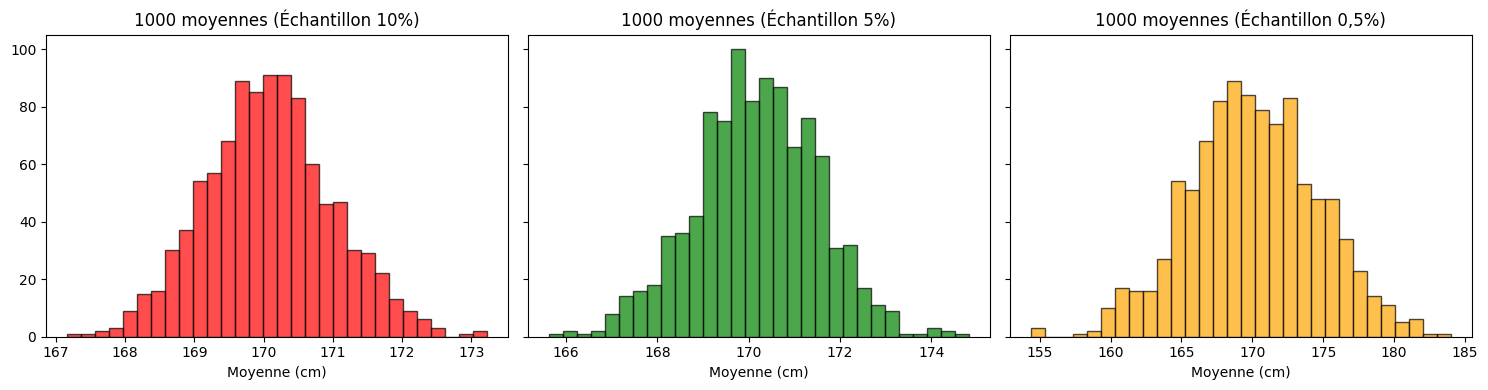

In [12]:
# Simulation Monte Carlo répétée (1000 itérations)
def simulate_means(sample_size, n_simulations=1000):
    means = []
    for _ in range(n_simulations):
        indices = np.random.choice(population_size, size=sample_size, replace=False)
        means.append(np.mean(population_data[indices]))
    return means

means_10 = simulate_means(100)
means_5 = simulate_means(50)
means_0_5 = simulate_means(5)

# Tracé des histogrammes des moyennes
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
axes[0].hist(means_10, bins=30, color='red', alpha=0.7, edgecolor='black')
axes[0].set_title("1000 moyennes (Échantillon 10%)")
axes[0].set_xlabel("Moyenne (cm)")

axes[1].hist(means_5, bins=30, color='green', alpha=0.7, edgecolor='black')
axes[1].set_title("1000 moyennes (Échantillon 5%)")
axes[1].set_xlabel("Moyenne (cm)")

axes[2].hist(means_0_5, bins=30, color='orange', alpha=0.7, edgecolor='black')
axes[2].set_title("1000 moyennes (Échantillon 0,5%)")
axes[2].set_xlabel("Moyenne (cm)")

plt.tight_layout()
plt.show()

Interprétation :
Les histogrammes montrent clairement que la dispersion (l'étalement) des moyennes est la plus grande pour l'échantillon de $0,5\ \%$ (courbe très large), et la plus faible pour l'échantillon de $10\ \%$ (courbe très resserrée autour de la vraie moyenne). Cela illustre le théorème central limite et confirme que la précision de l'estimation s'accroît à mesure que la taille de l'échantillon grandit.